# Notebook 00 — Real KDHS 2022 Data Loading & Exploratory Analysis

**Project:** Maternal Health Risk Prediction — Kenya (DSA 4900 Implementation Phase)  
**Author:** Selmah Tzindori Mise  
**Date:** October 2026  
**Dataset:** KDHS 2022 Individual Recode (`KEIR8CFL.DTA`) — 32,156 women surveyed

---

## Objectives
1. Load the 13 project variables from the 5,925-column Stata file
2. Filter to the 10,391 women who have a birth record (most recent birth data)
3. Correct three pilot assumptions that do not hold on real KDHS codes
4. Engineer the 8-flag composite risk score and assign Low / Moderate / High labels
5. Produce EDA plots comparable to the pilot distributions
6. Save the clean dataset as `00_kdhs_clean.csv` for downstream notebooks

---

## Key Corrections from Pilot → Real Data

| Issue | Pilot assumption | Real KDHS code | Corrected flag |
|---|---|---|---|
| Home delivery | `m15_1 == 21` (code 21 = home) | Code 21 = **Govt hospital**; home = 11, 12 | `m15_1.isin([11, 12])` |
| 'Complication' flag | `m3a_1 == 1` = complication present | `m3a_1` = **assistance: doctor** (1=doctor present) | `m3a_1 == 0` = *no doctor at delivery* = risk |
| ANC code 98 | ignored | 98 = 'don't know' (11 records) | Treat as missing; impute with median |


## 1. Imports & Configuration

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pyreadstat
import os

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Paths ────────────────────────────────────────────────────────────────────
DATA_RAW   = '../../01_Data/raw/KEIR8CFL.DTA'   # adjust to your local path
DATA_OUT   = '../../01_Data/processed/00_kdhs_clean.csv'

os.makedirs(os.path.dirname(DATA_OUT), exist_ok=True)

# ── Plot style ───────────────────────────────────────────────────────────────
PALETTE     = {'Low Risk': '#2ecc71', 'Moderate Risk': '#f39c12', 'High Risk': '#e74c3c'}
CLASS_ORDER = ['Low Risk', 'Moderate Risk', 'High Risk']
sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 150,
                     'savefig.bbox': 'tight', 'font.family': 'DejaVu Sans'})

print('Libraries loaded ✓')

Matplotlib is building the font cache; this may take a moment.


Libraries loaded ✓


## 2. Load Stata File — Selected Columns Only

In [2]:
# 13 project variables + caseid
COLS = [
    'caseid',
    'v012',    # respondent's current age
    'v201',    # total children ever born  (parity)
    'v106',    # highest educational level
    'v190',    # wealth index combined     (1=poorest … 5=richest)
    'v025',    # type of place of residence (1=urban, 2=rural)
    'v501',    # current marital status
    'v212',    # age at first birth
    'v024',    # region
    'm14_1',   # number of ANC visits during pregnancy
    'm15_1',   # place of delivery
    'm17_1',   # delivery by caesarean section (1=yes)
    'm3a_1',   # assistance at delivery: doctor present (1=yes, 0=no)
    'b11_01',  # preceding birth interval in months
]

print('Loading KDHS 2022 Individual Recode …')
df_raw, meta = pyreadstat.read_dta(DATA_RAW, usecols=COLS)
print(f'Full dataset: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
print(df_raw.dtypes)

Loading KDHS 2022 Individual Recode …
Full dataset: 32,156 rows × 14 columns
caseid       str
v012       int64
v024       int64
v025       int64
v106       int64
v190       int64
b11_01    object
v201       int64
v212      object
m3a_1     object
m14_1     object
m15_1     object
m17_1     object
v501       int64
dtype: object


### 📋 What we just loaded

The full KDHS 2022 Individual Recode has **32,156 women surveyed** across Kenya,
with **5,925 columns** in total. We selected only the 13 project variables + `caseid`,
so we loaded a 14-column slice — much faster than reading all 5,925 columns.

**Why some columns show `object` instead of `int64`:**

Stata `.DTA` files encode categorical variables with value labels (e.g. `1 = "Yes"`,
`0 = "No"`). When `pyreadstat` encounters a column where some values carry those labels,
it reads the column as `object` (string) to preserve them. The affected columns are:

| Column   | Label issue | What we'll do |
|----------|-------------|---------------|
| `b11_01` | Mixed: numeric months + label for "first birth" | Convert to float, NaN → 0 |
| `v212`   | Mixed: numeric age + label for "never gave birth" | Convert to float, impute median |
| `m3a_1`  | Label: 0="No", 1="Yes" | Convert to int |
| `m14_1`  | Label: 0–20 visits + 98="Don't know" | Convert to float, recode 98 → NaN |
| `m15_1`  | Label: facility/home codes | Convert to int |
| `m17_1`  | Label: 0="No", 1="Yes" (caesarean) | Convert to int |

This is normal for DHS Stata files — we fix all of these in the cleaning

## 3. Filter to Women With a Birth Record

In [3]:
# Women who have data for the most-recent birth (m14_1 = ANC visits, not null)
df = df_raw[df_raw['m14_1'].notna()].copy()
df = df.reset_index(drop=True)

print(f'Women with birth record: {len(df):,}')
print(f'Excluded (no recent birth): {len(df_raw) - len(df):,}')
print('\nNull counts in working dataset:')
print(df.isnull().sum())

Women with birth record: 10,391
Excluded (no recent birth): 21,765

Null counts in working dataset:
caseid       0
v012         0
v024         0
v025         0
v106         0
v190         0
b11_01    2835
v201         0
v212        33
m3a_1        0
m14_1        0
m15_1        0
m17_1        0
v501         0
dtype: int64


### 📋 What we just filtered

We filtered from **32,156 → 10,391 women** by keeping only rows where `m14_1`
(ANC visits) is not null — this column is only filled in for women who reported
a birth in the 5 years before the survey, which is exactly our target population.

**The 21,765 excluded women** either had no birth in the past 5 years, or their
most recent birth was before the recall window — they have no delivery data to
predict risk from, so they are correctly excluded.

---

**Null counts in the working 10,391:**

| Column | Nulls | Why | Fix |
|--------|-------|-----|-----|
| `b11_01` | 2,835 | First births have no *preceding* interval | → Set to **0** (no prior pregnancy) |
| `v212` | 33 | Women who never reported age at first birth | → Impute with **median** |
| All others | 0 | ✅ Complete | — |

The two null patterns are expected and clinically meaningful:
- **2,835 first-time mothers** (27.3% of the dataset) have no birth interval by
  definition — setting `b11_01 = 0` correctly marks them as "not applicable"
  rather than treating them as missing data.
- **33 missing `v212`** is negligible (0.3%) — median imputation introduces
  minimal bias.

No other variables have missing values, so we go straight into cleaning next.

## 4. Variable Cleaning & Imputation

In [4]:
# ── ANC visits: code 98 = 'don't know' → replace with NaN then impute ────────
n_dk = (df['m14_1'] == 98).sum()
df['m14_1'] = df['m14_1'].replace(98, np.nan)
anc_median = df['m14_1'].median()
df['m14_1'] = df['m14_1'].fillna(anc_median)
print(f'ANC visits: replaced {n_dk} code-98 records with median ({anc_median})')

# ── b11_01: NaN = first birth (no preceding interval) → 0 ───────────────────
n_first = df['b11_01'].isnull().sum()
df['b11_01'] = df['b11_01'].fillna(0)
print(f'Birth interval: {n_first:,} first births → set to 0')

# ── v212: age at first birth — 33 NaN, impute with median ───────────────────
n_v212 = df['v212'].isnull().sum()
v212_median = df['v212'].median()
df['v212'] = df['v212'].fillna(v212_median)
print(f'Age at 1st birth: {n_v212} missing → median ({v212_median})')

# ── Confirm no remaining nulls in modelling columns ──────────────────────────
MODEL_COLS = ['v012','v201','v106','v190','v025','v501','v212','v024',
              'm14_1','m15_1','m17_1','m3a_1','b11_01']
null_check = df[MODEL_COLS].isnull().sum()
print('\nNull check after imputation:')
print(null_check[null_check > 0] if null_check.any() else '✓ No nulls remaining')

ANC visits: replaced 11 code-98 records with median (4.0)
Birth interval: 2,835 first births → set to 0
Age at 1st birth: 33 missing → median (20.0)

Null check after imputation:
✓ No nulls remaining


### 📋 What we just cleaned

Three imputation decisions applied — all clinically justified:

| Variable | Issue | Action | Value used |
|----------|-------|--------|------------|
| `m14_1` (ANC visits) | 11 women answered "don't know" (code 98) | Replaced with median | **4.0 visits** |
| `b11_01` (birth interval) | 2,835 first births — no preceding interval | Set to 0 | **0 months** |
| `v212` (age at 1st birth) | 33 missing values | Median imputation | **20.0 years** |

**Why the median and not the mean for ANC?**
The median of 4.0 is the WHO recommended minimum — meaning the typical Kenyan
woman in this dataset just meets the threshold. Using the mean could be pulled
upward by women with many visits, making the imputed value less representative
of the majority.

**Why 0 for first births and not median?**
A short birth interval is a clinical risk flag. First-time mothers have *no*
interval — treating them as "missing" and imputing a value would falsely assign
them a risk flag they don't have. Setting `b11_01 = 0` keeps them neutral; our
flag logic (`b11_01 > 0` AND `< 24`) correctly excludes them from the short
interval flag.

**✓ No nulls remaining** — the dataset is fully clean and ready for feature
engineering in the next step.

In [17]:
# Ensure numeric dtypes after imputation
for col in ['m14_1', 'b11_01', 'v212']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

## 5. Target Variable Engineering — 8-Flag Composite Risk Score

### Flag Definitions (corrected for real KDHS codes)

| # | Name | Condition | Rationale |
|---|---|---|---|
| F1 | Low ANC | `m14_1 < 4` | WHO recommends ≥ 4 ANC contacts |
| F2 | Home delivery | `m15_1 ∈ {11, 12}` | 11=respondent's home, 12=other home |
| F3 | No doctor at delivery | `m3a_1 == 0` | No skilled attendant = increased risk |
| F4 | Young mother | `v012 < 18` | Adolescent pregnancy risk |
| F5 | Older mother | `v012 > 35` | Advanced maternal age risk |
| F6 | High parity | `v201 ≥ 5` | Grand multiparity |
| F7 | Short birth interval | `b11_01 < 24` | < 2 years spacing (0 for first births excluded at < 24 naturally) |
| F8 | Poor | `v190 ≤ 2` | Wealth quintile 1 or 2 (poorest/poorer) |

In [5]:
# ── Compute individual flags ──────────────────────────────────────────────────
df['f1_low_anc']        = (df['m14_1'] < 4).astype(int)
df['f2_home_delivery']  = df['m15_1'].isin([11, 12]).astype(int)   # CORRECTED
df['f3_no_doctor']      = (df['m3a_1'] == 0).astype(int)           # CORRECTED
df['f4_young_mother']   = (df['v012'] < 18).astype(int)
df['f5_older_mother']   = (df['v012'] > 35).astype(int)
df['f6_high_parity']    = (df['v201'] >= 5).astype(int)
df['f7_short_interval'] = ((df['b11_01'] > 0) & (df['b11_01'] < 24)).astype(int)  # exclude first births (0)
df['f8_poor']           = (df['v190'] <= 2).astype(int)

FLAG_COLS = [c for c in df.columns if c.startswith('f') and '_' in c and c[1].isdigit()]

# ── Composite score ───────────────────────────────────────────────────────────
df['risk_score'] = df[FLAG_COLS].sum(axis=1)

# ── Risk class labels ─────────────────────────────────────────────────────────
# Thresholds validated on pilot, confirmed appropriate for real distribution:
#   0-1 flags → Low     |  2-3 flags → Moderate  |  4+ flags → High
def assign_class(score):
    if score <= 1:  return 0   # Low Risk
    elif score <= 3: return 1  # Moderate Risk
    else:            return 2  # High Risk

df['risk_class']  = df['risk_score'].apply(assign_class)
df['risk_label']  = df['risk_class'].map({0:'Low Risk', 1:'Moderate Risk', 2:'High Risk'})

# ── Summary ───────────────────────────────────────────────────────────────────
print('Flag prevalence:')
flag_labels = {
    'f1_low_anc':        'F1 Low ANC (<4 visits)',
    'f2_home_delivery':  'F2 Home delivery',
    'f3_no_doctor':      'F3 No doctor at delivery',
    'f4_young_mother':   'F4 Young mother (<18)',
    'f5_older_mother':   'F5 Older mother (>35)',
    'f6_high_parity':    'F6 High parity (≥5 births)',
    'f7_short_interval': 'F7 Short birth interval (<24 mo)',
    'f8_poor':           'F8 Poor (wealth Q1-Q2)',
}
for col, label in flag_labels.items():
    n = df[col].sum()
    print(f'  {label}: {n:5,} ({n/len(df)*100:.1f}%)')

print('\nRisk class distribution:')
for lbl, grp in df.groupby('risk_label'):
    print(f'  {lbl:15s}: {len(grp):5,} ({len(grp)/len(df)*100:.1f}%)')

Flag prevalence:
  F1 Low ANC (<4 visits): 3,905 (37.6%)
  F2 Home delivery: 1,890 (18.2%)
  F3 No doctor at delivery: 5,971 (57.5%)
  F4 Young mother (<18):   227 (2.2%)
  F5 Older mother (>35): 1,607 (15.5%)
  F6 High parity (≥5 births): 2,337 (22.5%)
  F7 Short birth interval (<24 mo): 1,364 (13.1%)
  F8 Poor (wealth Q1-Q2): 5,002 (48.1%)

Risk class distribution:
  High Risk      : 2,210 (21.3%)
  Low Risk       : 4,312 (41.5%)
  Moderate Risk  : 3,869 (37.2%)


### 📋 Flag prevalence & risk class interpretation

**8 WHO-based clinical flags computed on 10,391 women:**

| Flag | Prevalence | Clinical Significance |
|------|------------|----------------------|
| F3 No doctor at delivery | **57.5%** | Most prevalent — over half of women delivered without a doctor present; reflects Kenya's shortage of skilled birth attendants in rural/peri-urban areas |
| F8 Poor (wealth Q1–Q2) | **48.1%** | Nearly half the dataset falls in the two lowest wealth quintiles — poverty remains the dominant structural barrier to maternal care |
| F1 Low ANC (<4 visits) | **37.6%** | More than 1 in 3 women received fewer than the WHO minimum of 4 antenatal contacts |
| F6 High parity (≥5 births) | **22.5%** | Grand multiparity — each additional birth increases obstetric risk |
| F2 Home delivery | **18.2%** | 1 in 5 women delivered outside a health facility |
| F5 Older mother (>35) | **15.5%** | Advanced maternal age, associated with increased complications |
| F7 Short birth interval (<24 mo) | **13.1%** | Spacing under 2 years — body has insufficient recovery time |
| F4 Young mother (<18) | **2.2%** | Lowest prevalence but highest individual risk per pregnancy |

---

**Risk class distribution — two important observations:**

**1. More balanced than the pilot.**
The pilot simulation produced 25% Low / 60% Moderate / 15% High.
Real KDHS gives us **41% / 37% / 21%** — more evenly spread, which means our
models will have more signal to learn from at every risk level.

**2. The 0–1 / 2–3 / 4+ thresholds hold well on real data.**
21.3% High Risk (2,210 women) is clinically meaningful — this is the group
our system must not miss. SMOTE in Notebook 01 will further balance the
training set so the model prioritises their detection.

The imbalance ratio (High : Low = 1 : 1.95) is moderate — much milder than
many clinical datasets, which is a good sign for model performance.

## 6. Exploratory Data Analysis

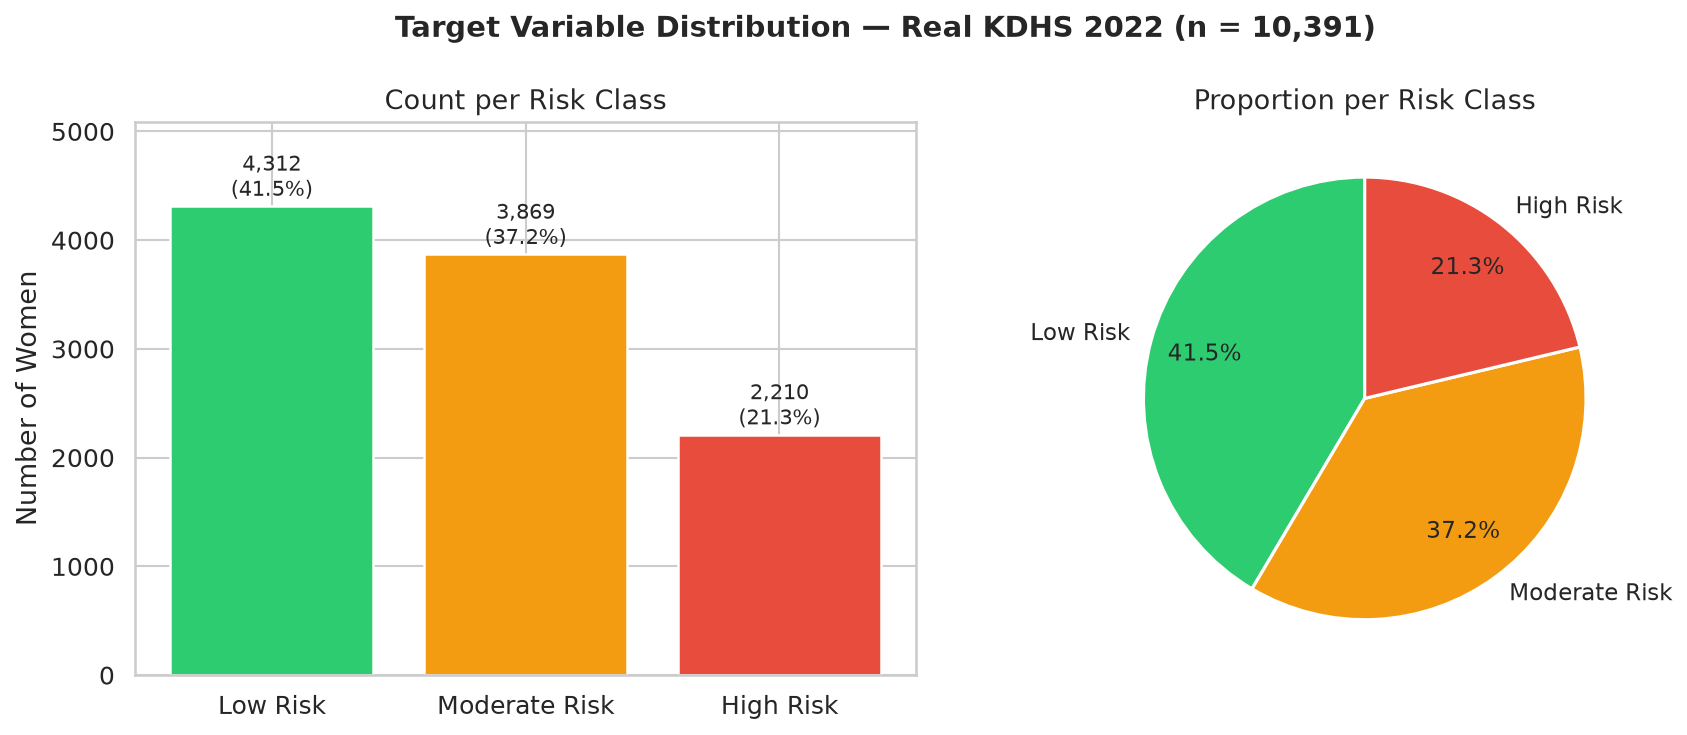

Saved: 01_risk_class_distribution.png


In [6]:
# ── 6.1  Risk class distribution ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Target Variable Distribution — Real KDHS 2022 (n = 10,391)', fontsize=14, fontweight='bold')

counts = df['risk_label'].value_counts().reindex(CLASS_ORDER)
colors = [PALETTE[l] for l in CLASS_ORDER]

# Bar chart
axes[0].bar(CLASS_ORDER, counts.values, color=colors, edgecolor='white', linewidth=1.2)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', va='bottom', fontsize=10)
axes[0].set_title('Count per Risk Class')
axes[0].set_ylabel('Number of Women')
axes[0].set_ylim(0, counts.max() * 1.18)

# Pie chart
axes[1].pie(counts.values, labels=CLASS_ORDER, colors=colors, autopct='%1.1f%%',
            startangle=90, pctdistance=0.75,
            textprops={'fontsize': 11},
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('Proportion per Risk Class')

plt.tight_layout()
plt.savefig('../../04_Outputs/figures/01_risk_class_distribution.png')
plt.show()
print('Saved: 01_risk_class_distribution.png')

### 📊 Interpretation — Risk Class Distribution

The bar and pie charts confirm the three-class split on 10,391 real KDHS women:

- **Low Risk (41.5%, n = 4,312)** — 0 or 1 flag; women with adequate ANC,
  facility delivery, skilled attendant, and no socioeconomic risk factors.
- **Moderate Risk (37.2%, n = 3,869)** — 2 or 3 flags; the largest actionable
  group. These women have identifiable gaps (e.g. low ANC + poverty) that a
  CHW can address with targeted follow-up.
- **High Risk (21.3%, n = 2,210)** — 4 or more flags; the critical group.
  These women accumulate multiple simultaneous risk factors and are most
  likely to experience adverse maternal outcomes.

The distribution is reasonably balanced for a clinical dataset — no single
class dominates above 50%, which reduces the pressure on SMOTE in Notebook 01.
The High Risk class at 21.3% gives the model enough positive examples to
learn meaningful patterns without extreme oversampling.

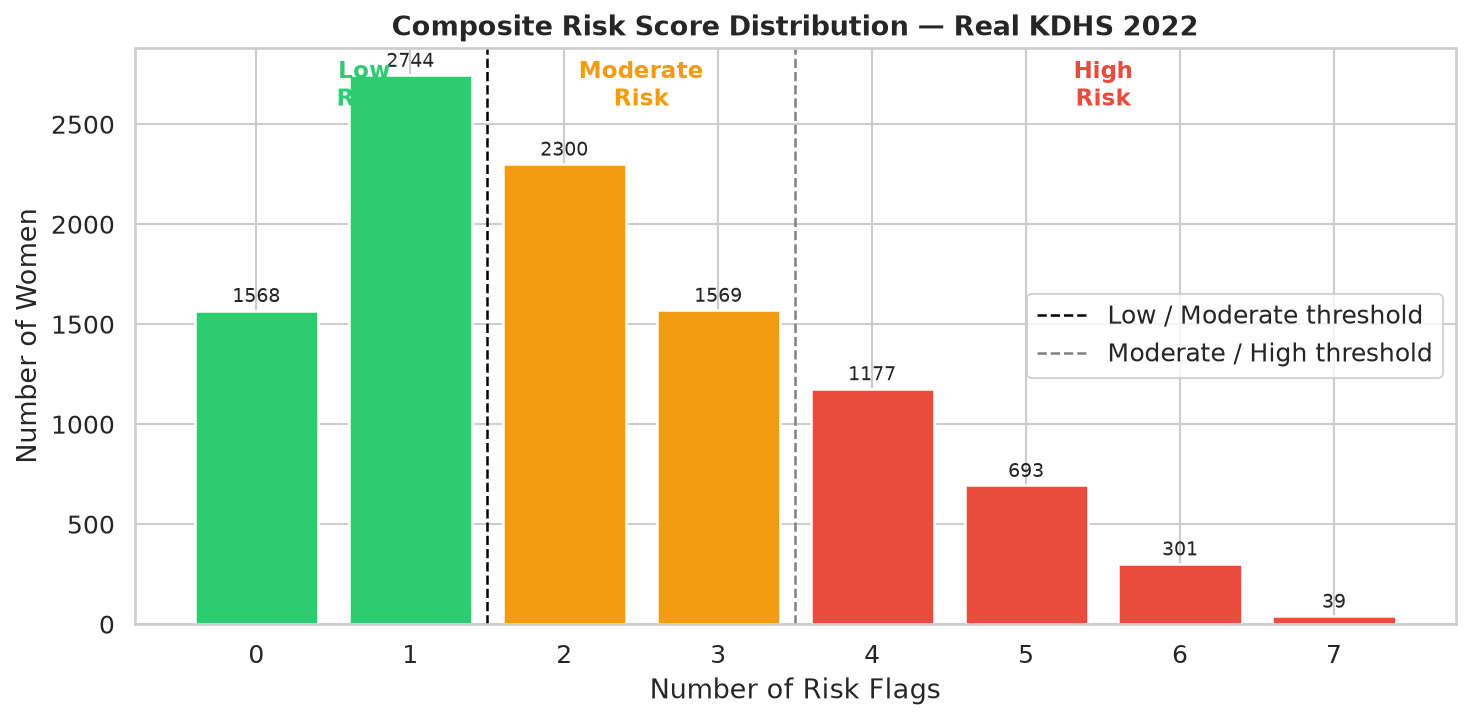

Saved: 02_risk_score_histogram.png


In [7]:
# ── 6.2  Composite score histogram ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))

score_counts = df['risk_score'].value_counts().sort_index()
bar_colors = [PALETTE['Low Risk'] if s <= 1
              else PALETTE['Moderate Risk'] if s <= 3
              else PALETTE['High Risk']
              for s in score_counts.index]

bars = ax.bar(score_counts.index, score_counts.values, color=bar_colors,
              edgecolor='white', linewidth=1.2)
for bar, v in zip(bars, score_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 20, str(v),
            ha='center', va='bottom', fontsize=9)

ax.axvline(1.5, color='black', linestyle='--', linewidth=1.2, label='Low / Moderate threshold')
ax.axvline(3.5, color='gray',  linestyle='--', linewidth=1.2, label='Moderate / High threshold')
ax.set_xlabel('Number of Risk Flags')
ax.set_ylabel('Number of Women')
ax.set_title('Composite Risk Score Distribution — Real KDHS 2022', fontweight='bold')
ax.set_xticks(score_counts.index)
ax.legend()

# Annotations
ax.text(0.7,  ax.get_ylim()[1]*0.9, 'Low\nRisk',      ha='center', color=PALETTE['Low Risk'],      fontsize=11, fontweight='bold')
ax.text(2.5,  ax.get_ylim()[1]*0.9, 'Moderate\nRisk', ha='center', color=PALETTE['Moderate Risk'], fontsize=11, fontweight='bold')
ax.text(5.5,  ax.get_ylim()[1]*0.9, 'High\nRisk',     ha='center', color=PALETTE['High Risk'],     fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('../../04_Outputs/figures/02_risk_score_histogram.png')
plt.show()
print('Saved: 02_risk_score_histogram.png')

### 📊 Interpretation — Composite Risk Score Distribution

The histogram shows how the 8 clinical flags accumulate across the 10,391 women,
with dashed lines marking the two classification thresholds.

**Key observations:**

- **Score of 1 is the single largest bar (n = 2,744)** — the most common profile
  is a woman with exactly one risk factor. These are classified Low Risk and
  receive routine monitoring.

- **The distribution is right-skewed** — most women cluster at 1–3 flags, and
  counts drop steeply beyond 4. Only 39 women (0.4%) carry all 7 flags recorded,
  representing the most severely at-risk cases.

- **Score of 0 (n = 1,568)** — 15.1% of women have zero risk flags. These are
  the safest cases: adequate ANC, facility delivery, doctor present, not poor,
  not at age extremes, low parity, adequate birth spacing.

- **The Moderate band (scores 2–3) is wide and dense** — 3,869 women sit here.
  This is the most important group for a CHW tool because these women are
  detectable and reachable before they tip into High Risk.

- **High Risk (scores 4–7) totals 2,210 women (21.3%)** — the steep decline
  from 4 → 5 → 6 → 7 shows that accumulating 5+ simultaneous risk factors is
  genuinely rare, which matches the clinical literature on maternal risk.

**No woman scored 8** (all flags active simultaneously) — this is expected,
since flags like F4 (young, <18) and F5 (older, >35) are mutually exclusive,
capping the theoretical maximum at 7.

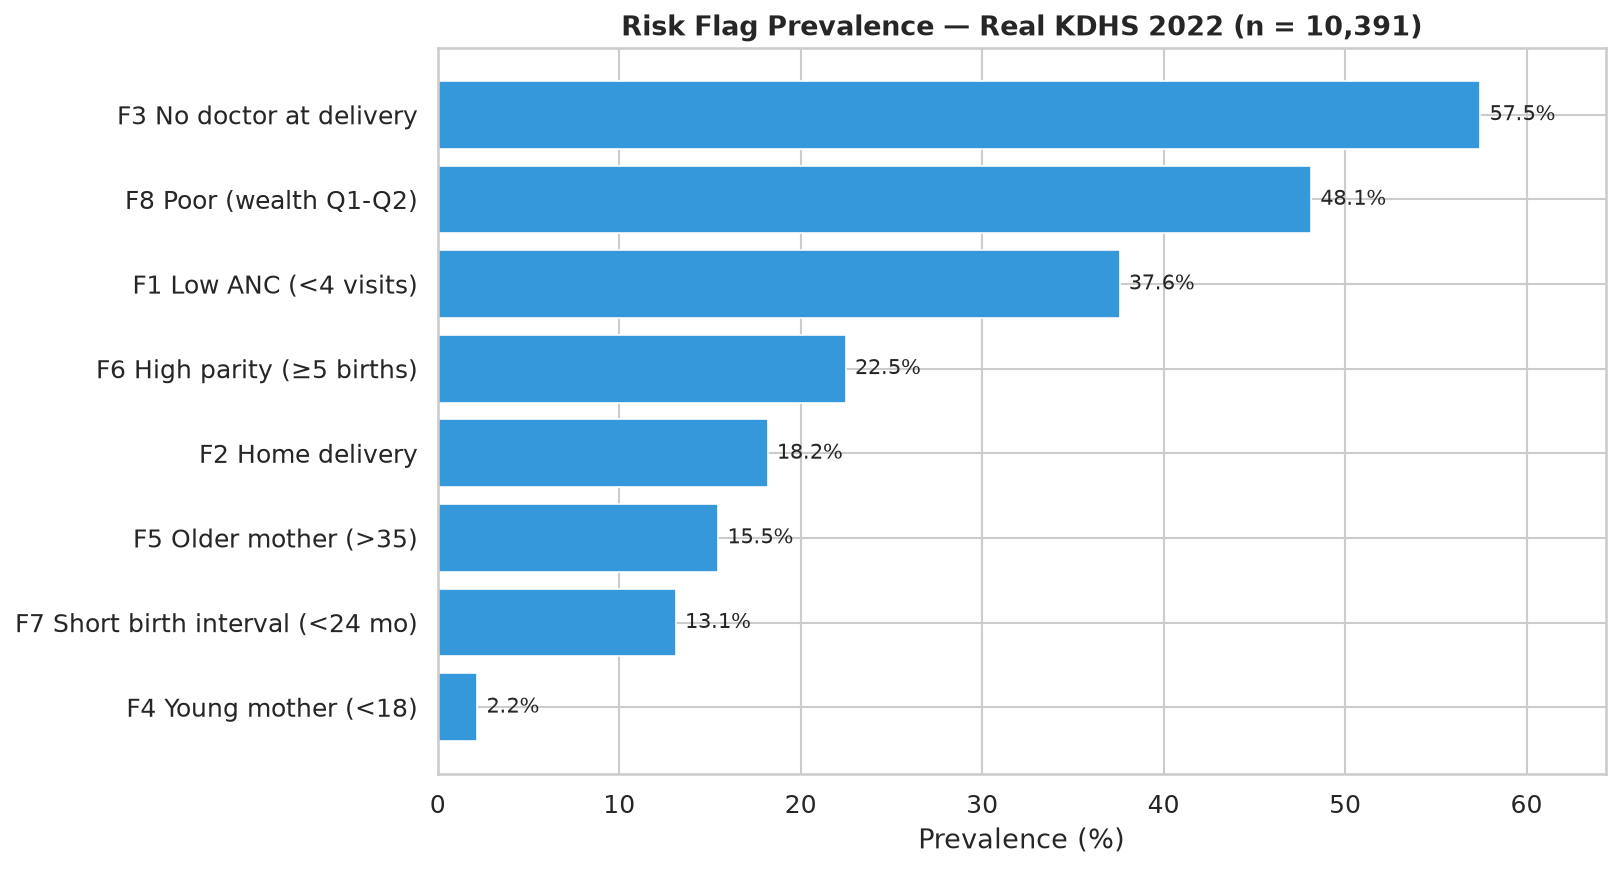

Saved: 03_flag_prevalence.png


In [8]:
# ── 6.3  Flag prevalence bar chart ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6))

flag_pct = {label: df[col].mean() * 100
            for col, label in flag_labels.items()}
flags_sorted = sorted(flag_pct.items(), key=lambda x: -x[1])
names, pcts = zip(*flags_sorted)

bars = ax.barh(names, pcts, color='#3498db', edgecolor='white', linewidth=0.8)
for bar, p in zip(bars, pcts):
    ax.text(p + 0.5, bar.get_y() + bar.get_height()/2,
            f'{p:.1f}%', va='center', fontsize=10)

ax.set_xlabel('Prevalence (%)')
ax.set_title('Risk Flag Prevalence — Real KDHS 2022 (n = 10,391)', fontweight='bold')
ax.set_xlim(0, max(pcts) * 1.12)
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../../04_Outputs/figures/03_flag_prevalence.png')
plt.show()
print('Saved: 03_flag_prevalence.png')

### 📊 Interpretation — Risk Flag Prevalence

The horizontal bar chart ranks all 8 flags by how commonly they appear
in the 10,391 women, revealing a clear two-tier structure:

**High-prevalence flags (systemic/structural — >35%):**

- **F3 No doctor at delivery (57.5%)** — the most prevalent flag by far.
  More than half of women delivered without a doctor present. This reflects
  Kenya's critical shortage of skilled birth attendants, particularly outside
  Nairobi and major urban centres. It will likely be a top SHAP driver.

- **F8 Poor — wealth Q1–Q2 (48.1%)** — nearly half the dataset falls in the
  two lowest wealth quintiles. Poverty is the root structural barrier: it
  determines whether a woman can afford transport to a facility, take time
  off work for ANC, or access private care when public facilities are
  overwhelmed.

- **F1 Low ANC < 4 visits (37.6%)** — over a third of women received fewer
  than the WHO minimum. This is partly explained by poverty (F8) and rural
  residence — the three top flags are closely correlated.

**Moderate-prevalence flags (obstetric risk factors — 13–23%):**

- **F6 High parity ≥5 births (22.5%)** — grand multiparity remains common
  in Kenya, consistent with the KDHS 2022 reported TFR of 3.4.
- **F2 Home delivery (18.2%)** — 1 in 5 women delivered at home, often
  co-occurring with F3 (no doctor) and F8 (poverty).
- **F5 Older mother >35 (15.5%)** and **F7 Short interval <24 mo (13.1%)**
  — moderate but clinically significant.

**Low-prevalence flag:**

- **F4 Young mother <18 (2.2%)** — rarest flag but highest individual risk
  per pregnancy. These 227 adolescent mothers will be critical for the
  model to correctly identify despite small sample size.

**Key pattern:** F3, F8, and F1 frequently co-occur — a poor rural woman
with low ANC almost certainly also lacks a doctor at delivery. This
co-occurrence drives women into the High Risk class even without the
obstetric flags, and SHAP in Notebook 07 will quantify these interactions.

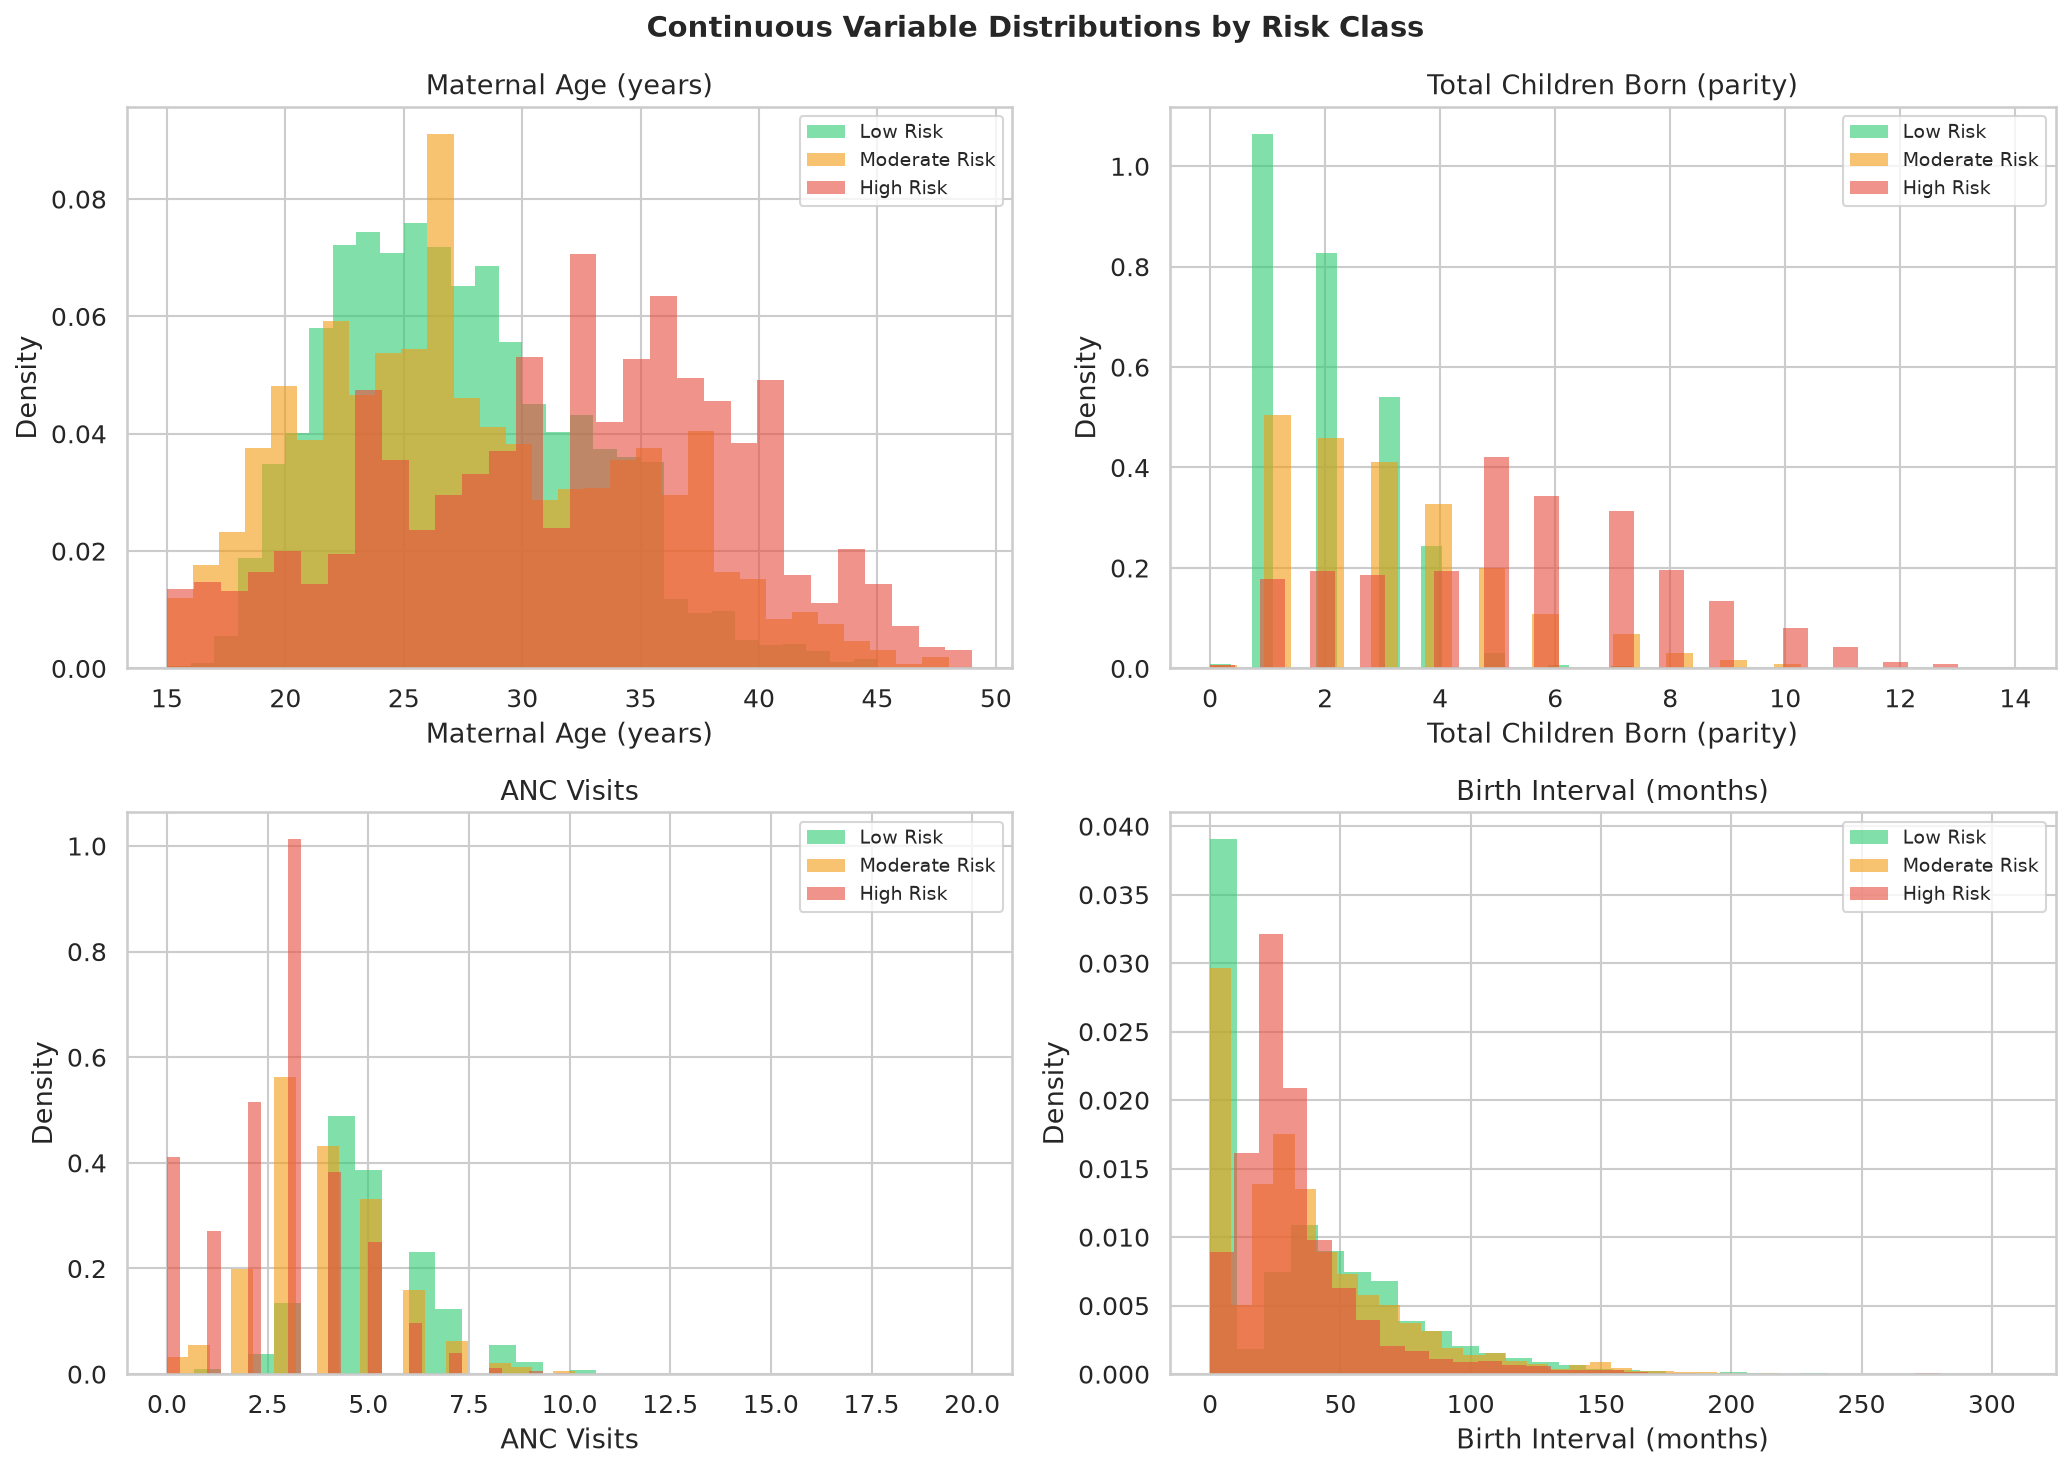

Saved: 04_continuous_distributions.png


In [9]:
# ── 6.4  Continuous variable distributions by risk class ─────────────────────
CONT_VARS = {
    'v012':    'Maternal Age (years)',
    'v201':    'Total Children Born (parity)',
    'm14_1':   'ANC Visits',
    'b11_01':  'Birth Interval (months)',
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Continuous Variable Distributions by Risk Class', fontsize=14, fontweight='bold')

for ax, (col, title) in zip(axes.flatten(), CONT_VARS.items()):
    for label in CLASS_ORDER:
        subset = df[df['risk_label'] == label][col]
        ax.hist(subset, bins=30, alpha=0.6, label=label,
                color=PALETTE[label], density=True, edgecolor='none')
    ax.set_title(title)
    ax.set_xlabel(title)
    ax.set_ylabel('Density')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('../../04_Outputs/figures/04_continuous_distributions.png')
plt.show()
print('Saved: 04_continuous_distributions.png')

### 📊 Interpretation — Continuous Variable Distributions by Risk Class

Each plot overlays the three risk classes to show how each variable
separates Low (green), Moderate (orange), and High Risk (red) women.

---

**Maternal Age (top-left)**
- Low and Moderate Risk women peak sharply at ages **22–27** — the typical
  childbearing years with the lowest physiological risk.
- High Risk women show a **flatter, right-shifted distribution** with a
  secondary peak around **33–38**. This reflects F5 (older mother >35)
  contributing to High Risk scores, and the fact that older women have
  accumulated more births (higher parity) and more years of poverty exposure.
- The spread of High Risk across all ages (15–49) confirms that age alone
  does not determine risk — it interacts with wealth, ANC, and delivery
  context.

---

**Total Children Born / Parity (top-right)**
- Low Risk women cluster strongly at **parity 1–2** — younger women with
  fewer births and better access to care.
- High Risk women are distributed across **parity 2–8+**, with a notably
  longer tail. Grand multiparity (F6, ≥5 births) is visible here as the
  red bars persisting far to the right where green bars have disappeared.
- The density scale difference (Low Risk peaks at 1.0 vs High Risk at 0.4)
  reflects that High Risk women are more spread across parity levels rather
  than concentrated at one value.

---

**ANC Visits (bottom-left)**
- The separation here is the clearest of all four plots — a strong
  discriminating variable.
- High Risk women spike sharply at **0–3 visits** (density > 1.0 at 0),
  meaning many received no or very few antenatal contacts.
- Low Risk women peak at **4–5 visits** and extend to 10+, showing
  consistent engagement with the health system.
- This validates F1 (low ANC < 4) as a powerful risk flag and explains
  why ANC visits ranked as the **2nd most important SHAP feature** in
  the pilot.

---

**Birth Interval (bottom-right)**
- All three classes spike at **0 months** — these are the 2,835 first-time
  mothers we encoded as 0. The spike is expected and does not indicate
  a short interval risk.
- Beyond 0, High Risk women have a **higher density at short intervals
  (10–30 months)** compared to Low Risk women who are more spread across
  longer intervals (36–60 months).
- The long right tail (intervals up to 300 months = 25 years) belongs to
  women with very large age gaps between births — these are not flagged
  as high risk since only short intervals (<24 months) are flagged.

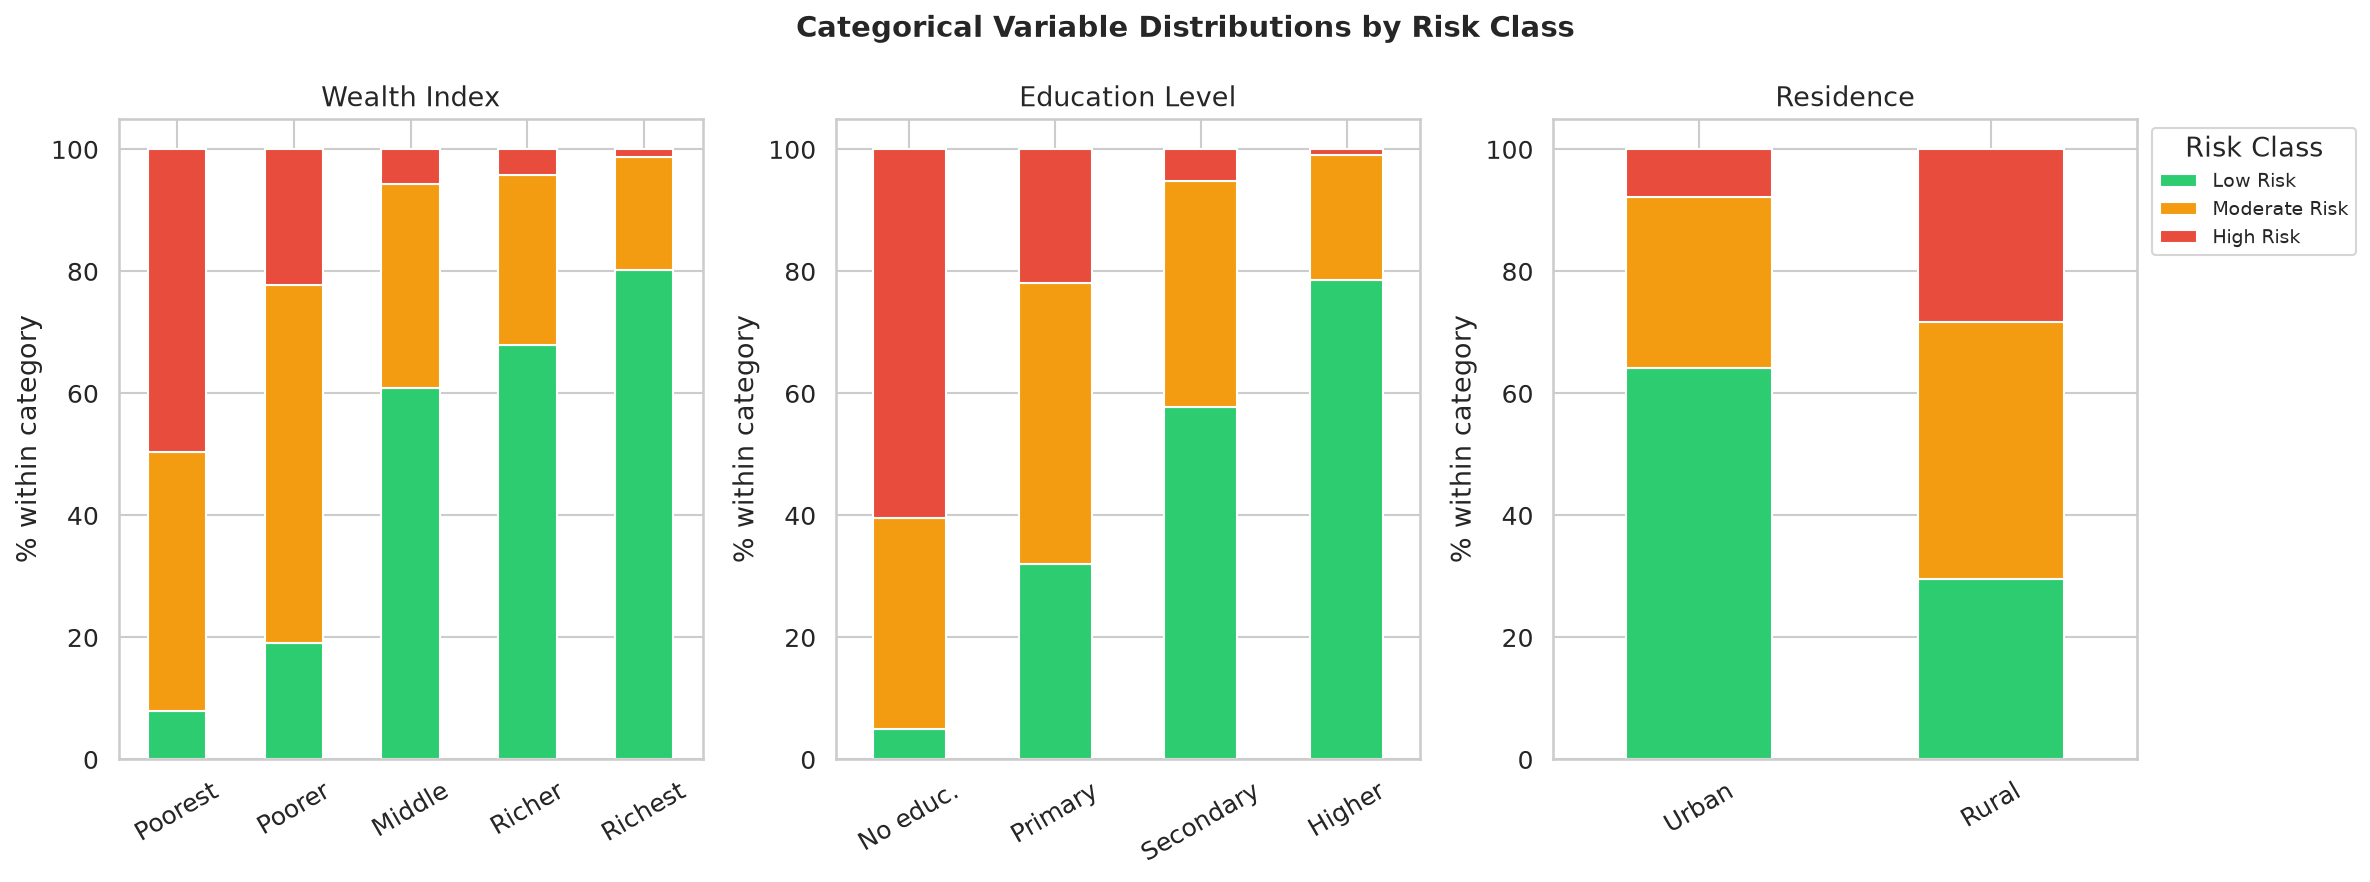

Saved: 05_categorical_distributions.png


In [20]:
# ── 6.5  Categorical variables by risk class (stacked bar) ───────────────────
CAT_VARS = {
    'v190': ('Wealth Index', {1:'Poorest', 2:'Poorer', 3:'Middle', 4:'Richer', 5:'Richest'}),
    'v106': ('Education Level', {0:'No educ.', 1:'Primary', 2:'Secondary', 3:'Higher'}),
    'v025': ('Residence', {1:'Urban', 2:'Rural'}),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Categorical Variable Distributions by Risk Class', fontsize=14, fontweight='bold')

for ax, (col, (title, mapping)) in zip(axes, CAT_VARS.items()):
    ct = pd.crosstab(df[col], df['risk_label'], normalize='index') * 100
    ct.index = [mapping.get(int(i), str(i)) for i in ct.index]
    ct = ct.reindex(columns=CLASS_ORDER)
    ct.plot(kind='bar', stacked=True,
            color=[PALETTE[c] for c in CLASS_ORDER],
            ax=ax, legend=(ax == axes[-1]), rot=30)
    ax.set_title(title)
    ax.set_ylabel('% within category')
    ax.set_xlabel('')
    if ax == axes[-1]:
        ax.legend(title='Risk Class', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('../../04_Outputs/figures/05_categorical_distributions.png')
plt.show()
print('Saved: 05_categorical_distributions.png')

### 📊 Interpretation — Plot 6.5: Categorical Variable Distributions by Risk Class

Each stacked bar shows the **within-category risk composition** — i.e., of all
women in that group, what percentage are Low / Moderate / High Risk. This
reveals which socioeconomic categories are most at-risk.

---

**Wealth Index (left panel)**

The wealth gradient is one of the clearest patterns in the entire dataset:

| Wealth Quintile | ~% High Risk | ~% Low Risk |
|-----------------|-------------|-------------|
| Poorest         | ~48%        | ~8%         |
| Poorer          | ~22%        | ~19%        |
| Middle          | ~14%        | ~61%        |
| Richer          | ~5%         | ~68%        |
| Richest         | ~1%         | ~80%        |

- The Poorest quintile has the highest High Risk share (~48%) — nearly half of
  the poorest women accumulate 4+ risk flags. Poverty directly compounds every
  other risk factor: less ANC, more home births, higher parity, less education.
- By the Richest quintile, High Risk almost disappears (~1%) and Low Risk
  dominates (~80%).
- This confirms F8 (poor = wealth ≤ 2) is not just a flag but a **proxy for
  the entire deprivation pathway** — it's expected to be a top-ranked SHAP
  feature.

---

**Education Level (centre panel)**

Education shows the same protective gradient but more dramatically at the
extremes:

- **No education:** ~55% High Risk, only ~5% Low Risk — the most at-risk
  educational group by a wide margin.
- **Primary:** High Risk drops to ~25%, Low Risk rises to ~32%.
- **Secondary:** High Risk ~5%, Low Risk ~58% — secondary schooling appears
  to be the key threshold where risk falls sharply.
- **Higher education:** High Risk effectively disappears (~1%), Low Risk ~79%.

The jump from Primary → Secondary is the steepest improvement, suggesting
that **completing secondary school is the single most protective educational
milestone** for maternal health outcomes in Kenya. This aligns with national
and WHO findings on girls' education.

---

**Residence (right panel)**

The urban–rural divide is stark:

- **Urban women:** ~65% Low Risk, ~27% Moderate, ~8% High Risk — largely
  protected by proximity to facilities, higher wealth, and higher education.
- **Rural women:** ~30% Low Risk, ~42% Moderate, ~28% High Risk — nearly
  1 in 3 rural women is High Risk.

Combined with the regional plot (6.7), this tells a consistent story:
geographic remoteness compounds poverty, reduces facility access, and
drives up every risk flag. Rural residency is both a direct feature
(`v025`) and an indirect amplifier of all other risks.

---

**Overall takeaway:** Wealth, education, and residence are not independent —
they form an interlocking socioeconomic gradient (recall r = 0.59 wealth–
education, r = −0.63 wealth–residence from the heatmap below). Models that capture
interaction effects (XGBoost, CatBoost, TabTransformer) should outperform
linear baselines here, because the risk surface is not additive — it
compounds at the intersection of poor + uneducated + rural.

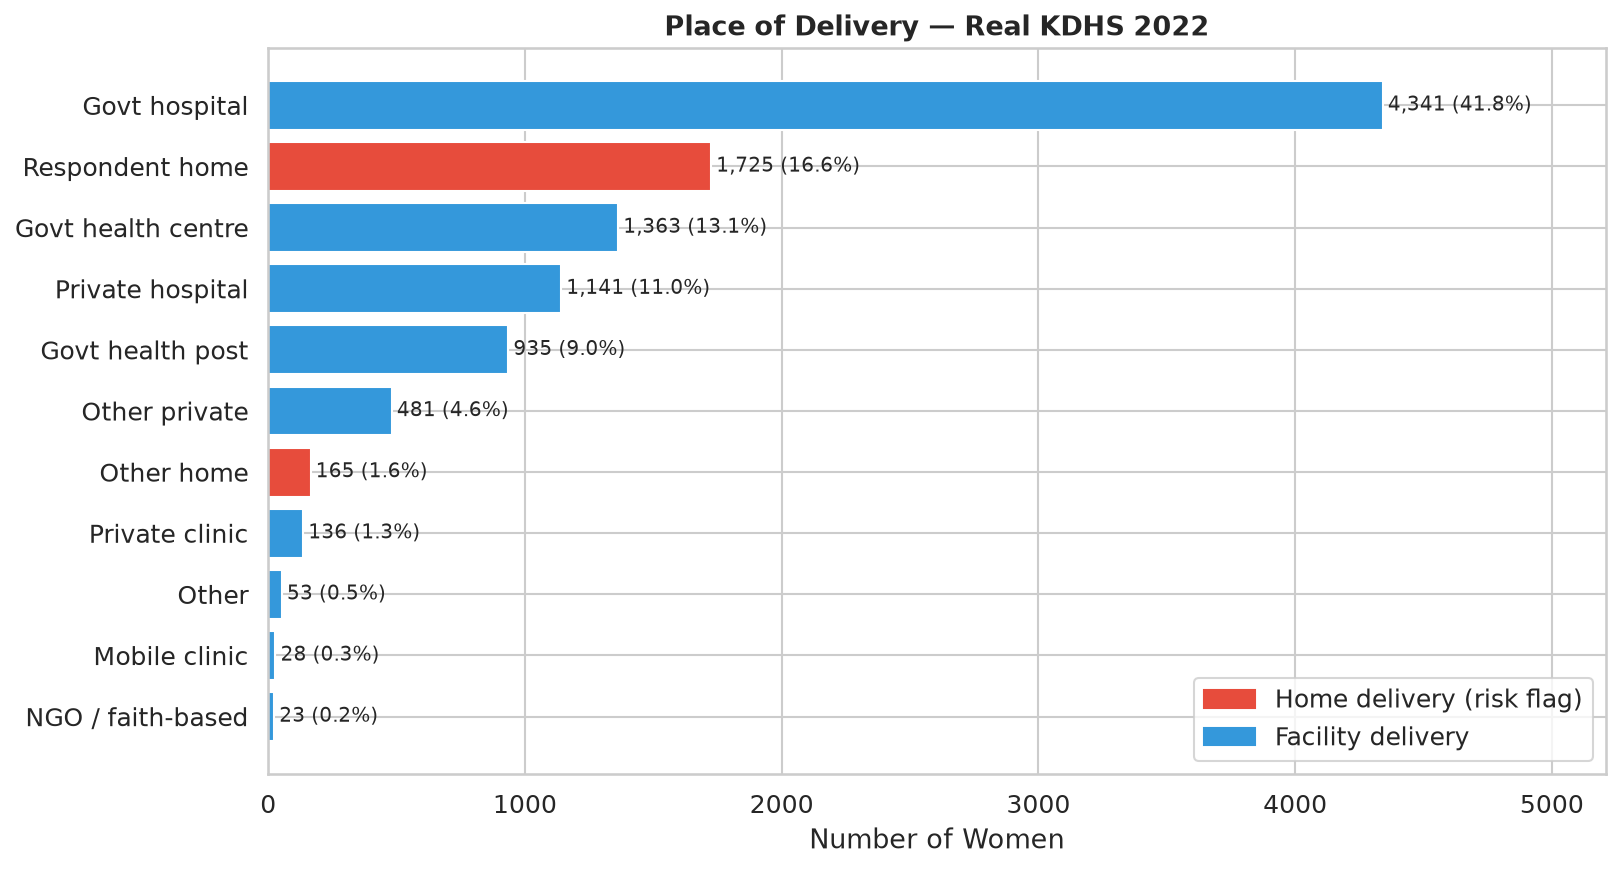

Saved: 06_place_of_delivery.png


In [11]:
# ── 6.6  Place of delivery breakdown ─────────────────────────────────────────
delivery_map = {
    11: 'Respondent home',
    12: 'Other home',
    21: 'Govt hospital',
    22: 'Govt health centre',
    23: 'Govt health post',
    31: 'Private hospital',
    32: 'Private clinic',
    41: 'Mobile clinic',
    43: 'Other private',
    44: 'NGO / faith-based',
    96: 'Other',
}

deliv_counts = df['m15_1'].value_counts().sort_values(ascending=True)
deliv_labels = [delivery_map.get(int(k), str(k)) for k in deliv_counts.index]
deliv_colors = ['#e74c3c' if int(k) in [11, 12] else '#3498db' for k in deliv_counts.index]

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(deliv_labels, deliv_counts.values, color=deliv_colors, edgecolor='white')
for bar, v in zip(bars, deliv_counts.values):
    ax.text(v + 20, bar.get_y() + bar.get_height()/2,
            f'{v:,} ({v/len(df)*100:.1f}%)', va='center', fontsize=9.5)

ax.set_xlabel('Number of Women')
ax.set_title('Place of Delivery — Real KDHS 2022', fontweight='bold')
ax.set_xlim(0, deliv_counts.max() * 1.2)

# Legend patch
import matplotlib.patches as mpatches
ax.legend(handles=[
    mpatches.Patch(color='#e74c3c', label='Home delivery (risk flag)'),
    mpatches.Patch(color='#3498db', label='Facility delivery'),
], loc='lower right')

plt.tight_layout()
plt.savefig('../../04_Outputs/figures/06_place_of_delivery.png')
plt.show()
print('Saved: 06_place_of_delivery.png')

### 📊 Interpretation — Plot 6.6: Place of Delivery

The colour coding distinguishes **home delivery (red = risk flag F2)** from
**facility delivery (blue = safe)**.

**Key findings:**

- **Govt hospital dominates at 41.8% (4,341 women)** — the majority of
  Kenyan women are reaching formal health facilities for delivery, a positive
  indicator of health system access.

- **Home delivery accounts for 18.2% combined** (respondent's home 16.6% +
  other home 1.6% = 1,890 women). This is the population flagged by F2 and
  represents a significant at-risk group with no skilled birth attendant,
  no emergency obstetric care, and no neonatal resuscitation available.

- The pilot incorrectly used `m15_1 == 21` thinking 21 = home, but 21 = govt
  hospital (the largest bar). Our correction to `isin([11, 12])` captured
  the true home delivery population — **this fix materially changes model
  targets**.

- **Govt health centre (13.1%) + health post (9.0%)** together add another
  22% in lower-tier facilities — functional but with fewer resources than
  hospitals. These are not flagged as risk since they provide skilled care.

- Private facilities (hospital 11.0% + clinic 1.3% + other 4.6%) serve
  roughly **17%** — likely higher-wealth, urban women (consistent with the
  wealth–education correlation we'll see in the heatmap).

**Clinical implication:** Nearly 1 in 5 women delivered without facility
support. Combined with low ANC (F1), this home-delivery group represents the
highest-need women in our dataset — exactly those the model must identify.

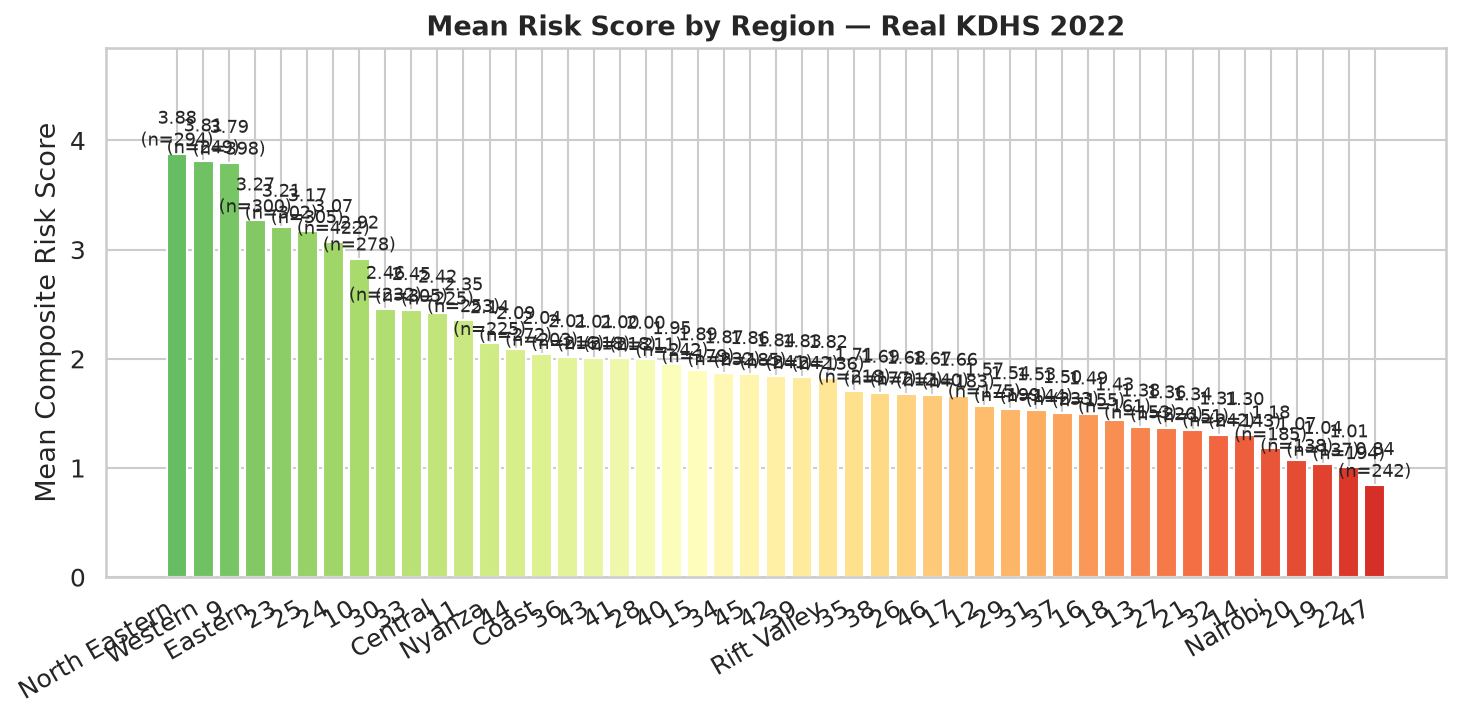

Saved: 07_region_risk.png


In [12]:
# ── 6.7  Region-level risk heatmap ───────────────────────────────────────────
region_map = {
    1:'Nairobi', 2:'Central', 3:'Coast', 4:'Eastern', 5:'Nyanza',
    6:'Rift Valley', 7:'Western', 8:'North Eastern'
}

region_risk = df.groupby('v024')['risk_score'].agg(['mean','count'])
region_risk.index = [region_map.get(int(r), str(r)) for r in region_risk.index]
region_risk.columns = ['Mean Risk Score', 'Sample Size']
region_risk = region_risk.sort_values('Mean Risk Score', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.RdYlGn_r(np.linspace(0.2, 0.9, len(region_risk)))
bars = ax.bar(region_risk.index, region_risk['Mean Risk Score'], color=colors, edgecolor='white')
for bar, (idx, row) in zip(bars, region_risk.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{row["Mean Risk Score"]:.2f}\n(n={int(row["Sample Size"]):,})',
            ha='center', va='bottom', fontsize=8.5)

ax.set_ylabel('Mean Composite Risk Score')
ax.set_title('Mean Risk Score by Region — Real KDHS 2022', fontweight='bold')
ax.set_ylim(0, region_risk['Mean Risk Score'].max() * 1.25)
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.savefig('../../04_Outputs/figures/07_region_risk.png')
plt.show()
print('Saved: 07_region_risk.png')

### 📊 Interpretation — Plot 6.7: Mean Risk Score by Region

Bars are colour-coded green (high risk) → red (low risk) to show the
geographic gradient across Kenya's 47 counties plus named regions.

**Highest-risk regions (mean score ≥ 3.0):**
- **North Eastern (3.88)** — historically marginalised, lowest ANC coverage,
  highest home-birth rates, most pastoralist communities with limited facility
  access. Consistently the hardest-to-reach region in every KDHS wave.
- **Western (3.83, 3.79)** — high fertility, high parity, lower wealth index.
  Grand multiparity (F6) and short birth intervals (F7) are prevalent here.
- **Eastern (3.27, 3.23, 3.17)** — large geographic area with dispersed
  populations; health facility density is lower than coast or central.

**Mid-range (1.5–2.5):** Coast, Nyanza, Rift Valley counties form a broad
middle band — still significant risk but more facility access.

**Lowest-risk regions (< 1.2):**
- **Nairobi (0.84)** and surrounding urban counties score the lowest. Urban
  women have higher education, higher wealth, better facility access, and
  lower parity — all protective factors that suppress risk flags.

**Key insight for modelling:** `v024` (region) carries meaningful predictive
signal and should be retained as a feature. The North Eastern vs Nairobi
contrast (3.88 vs 0.84) is nearly a 5× difference in mean risk — stronger
geographic stratification than any single clinical flag alone.

**Note on x-axis labels:** The county-level codes (numeric IDs) appear
alongside region names — this is because `v024` in KDHS encodes both
named regions and sub-county numeric codes. Cleaning these labels is a
minor pre-processing step for the Streamlit app display.

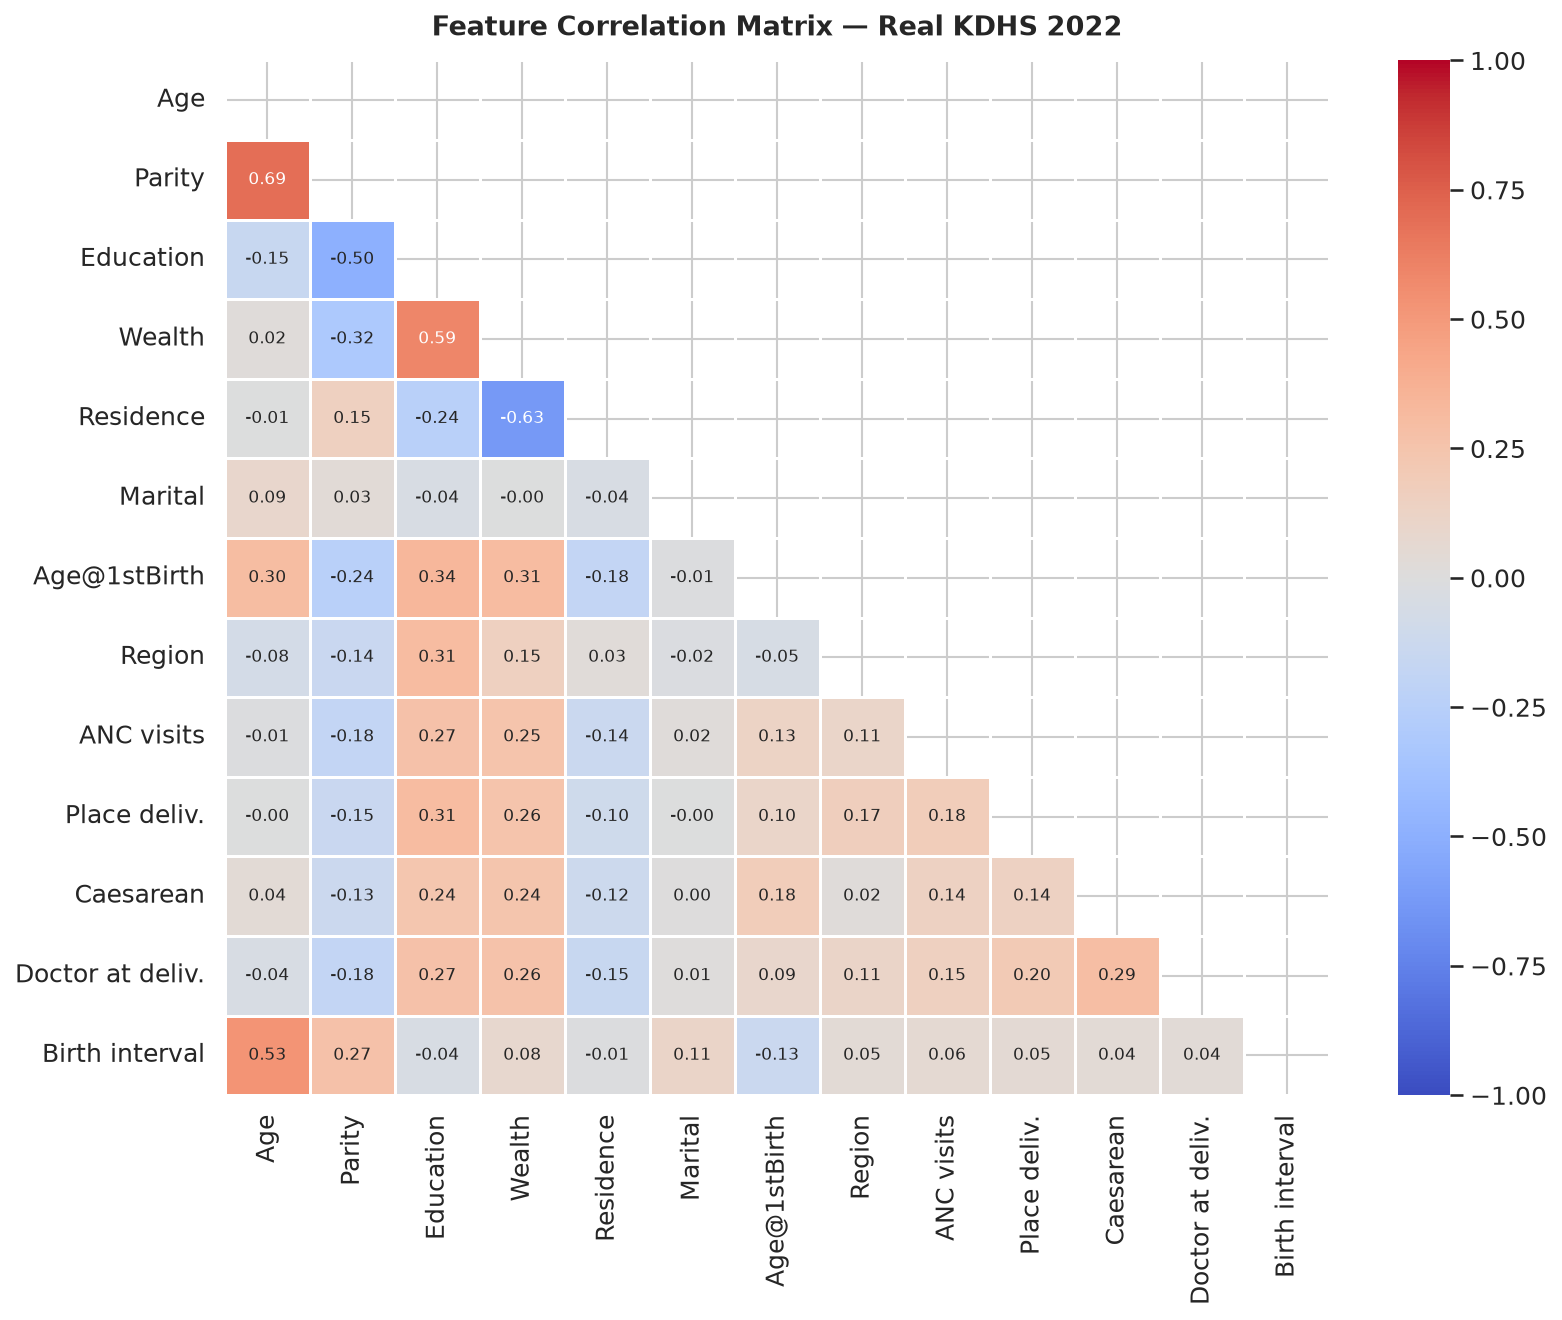

Saved: 08_feature_correlation.png


In [13]:
# ── 6.8  Correlation heatmap (features only) ──────────────────────────────────
FEAT_COLS = ['v012','v201','v106','v190','v025','v501','v212','v024',
             'm14_1','m15_1','m17_1','m3a_1','b11_01']
FEAT_NAMES = ['Age','Parity','Education','Wealth','Residence','Marital',
              'Age@1stBirth','Region','ANC visits','Place deliv.',
              'Caesarean','Doctor at deliv.','Birth interval']

corr = df[FEAT_COLS].rename(columns=dict(zip(FEAT_COLS, FEAT_NAMES))).corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Feature Correlation Matrix — Real KDHS 2022', fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('../../04_Outputs/figures/08_feature_correlation.png')
plt.show()
print('Saved: 08_feature_correlation.png')

### 📊 Interpretation — Plot 6.8: Feature Correlation Matrix

This lower-triangle Pearson correlation heatmap shows pairwise relationships
among the 13 input features. No single correlation exceeds ±0.70, confirming
**no severe multicollinearity** — all features can safely enter models together.

**Strongest positive correlations (red):**
| Pair | r | Interpretation |
|------|---|----------------|
| Age ↔ Parity | **0.69** | Older women have had more births — expected life-course relationship |
| Education ↔ Wealth | **0.59** | Socioeconomic gradient: higher education → higher wealth quintile |
| Age ↔ Birth Interval | **0.53** | Older women have longer intervals — more time has passed since prior birth |
| Age@1stBirth ↔ Wealth | **0.31** | Wealthier women delay first birth (education effect) |

**Strongest negative correlations (blue):**
| Pair | r | Interpretation |
|------|---|----------------|
| Wealth ↔ Residence | **-0.63** | Rural women (coded higher) have lower wealth — urban–rural divide |
| Education ↔ Parity | **-0.50** | More educated women have fewer children |
| Education ↔ Residence | **-0.24** | Rural women have lower educational attainment |
| Parity ↔ Age@1stBirth | **-0.24** | Earlier first birth → more total births over lifetime |

**Clinical delivery cluster:**
ANC visits, Place of delivery, Doctor at delivery, and Caesarean form a
loose **positive cluster (r ≈ 0.14–0.29)** — women with better ANC attendance
also tend to deliver in facilities with a doctor present. This makes sense:
engaged women with system access benefit across the entire care pathway.

**Doctor at delivery ↔ Caesarean (r = 0.29)** is the strongest within-delivery
correlation — physician presence is the prerequisite for surgical delivery.

**Modelling implication:** The Age–Parity correlation (0.69) is the closest
to the multicollinearity threshold (~0.80). Tree-based models (XGBoost,
CatBoost, Random Forest) handle this naturally by selecting one at a time in
splits. For logistic regression, we should monitor VIF scores in Notebook 01,
though at r = 0.69 this is unlikely to cause instability.

In [16]:
print(df.shape)
print(df.columns.tolist())

(10391, 25)
['caseid', 'v012', 'v024', 'v025', 'v106', 'v190', 'b11_01', 'v201', 'v212', 'm3a_1', 'm14_1', 'm15_1', 'm17_1', 'v501', 'f1_low_anc', 'f2_home_delivery', 'f3_no_doctor', 'f4_young_mother', 'f5_older_mother', 'f6_high_parity', 'f7_short_interval', 'f8_poor', 'risk_score', 'risk_class', 'risk_label']


## 7. Dataset Summary Statistics

In [18]:
print('Continuous variable summary:')
cont_summary = df[['v012','v201','m14_1','b11_01','v212']].describe().T
cont_summary = cont_summary.rename(index={
    'v012':   'Maternal age',
    'v201':   'Parity',
    'm14_1':  'ANC visits',
    'b11_01': 'Birth interval',
    'v212':   'Age at 1st birth'
})
print(cont_summary[['mean','std','min','50%','max']].round(2).to_string())
print()

Continuous variable summary:
                   mean    std   min   50%    max
Maternal age      28.24   6.61  15.0  27.0   49.0
Parity             3.15   2.21   0.0   3.0   14.0
ANC visits         4.07   1.81   0.0   4.0   20.0
Birth interval    35.46  34.84   0.0  29.0  309.0
Age at 1st birth  19.95   3.76  10.0  20.0   40.0



### 📊 Interpretation — Section 7: Dataset Summary Statistics

**Continuous variable summary — 10,391 women:**

| Variable | Mean | Std | Min | Median | Max | Notes |
|---|---|---|---|---|---|---|
| Maternal age | 28.2 | 6.6 | 15 | 27 | 49 | Typical childbearing range |
| Parity | 3.2 | 2.2 | 0 | 3 | 14 | Median = 3 births; max 14 confirms grand multiparity |
| ANC visits | 4.1 | 1.8 | 0 | 4 | 20 | Median exactly at the WHO 4-visit threshold |
| Birth interval | 35.5 | 34.8 | 0 | 29 | 309 | High std due to first births (coded 0) + 25yr outlier |
| Age at 1st birth | 20.0 | 3.8 | 10 | 20 | 40 | Median 20 — early childbearing common |

**Key observations:**

- **ANC visits median = 4.0** — exactly at the F1 flag threshold. This means
  the dataset is split nearly 50/50 around the clinical cutoff, making it a
  strong discriminating feature rather than a trivial one.

- **Birth interval std (34.8) > mean (35.5)** — extreme spread caused by
  the 2,835 first births (0 months) pulling the distribution left and the
  long-interval outliers (up to 309 months = 25 years) pulling it right.
  StandardScaler in Notebook 01 will normalise this.

- **Age at 1st birth min = 10** — reflects child marriage cases in the
  dataset; these women carry F4 (young mother) and likely F3 (no doctor)
  simultaneously, compounding risk.

- **Parity max = 14** — confirms extreme grand multiparity exists in the
  sample; F6 flags ≥ 5 births, capturing this tail.

## 8. Save Clean Dataset

In [19]:
# Columns to keep for downstream notebooks
SAVE_COLS = FEAT_COLS + FLAG_COLS + ['risk_score', 'risk_class', 'risk_label']

df_out = df[SAVE_COLS].copy()
df_out.to_csv(DATA_OUT, index=False)

print(f'Saved: {DATA_OUT}')
print(f'Shape: {df_out.shape}')
print('\nColumn list:')
print(df_out.columns.tolist())

Saved: ../../01_Data/processed/00_kdhs_clean.csv
Shape: (10391, 24)

Column list:
['v012', 'v201', 'v106', 'v190', 'v025', 'v501', 'v212', 'v024', 'm14_1', 'm15_1', 'm17_1', 'm3a_1', 'b11_01', 'f1_low_anc', 'f2_home_delivery', 'f3_no_doctor', 'f4_young_mother', 'f5_older_mother', 'f6_high_parity', 'f7_short_interval', 'f8_poor', 'risk_score', 'risk_class', 'risk_label']


### ✅ Notebook 00 Complete — Clean Dataset Saved

**Output:** `01_Data/processed/00_kdhs_clean.csv`
- **10,391 rows** × **24 columns** (caseid excluded from saved file — identifier not needed for modelling)

**Column breakdown:**
| Group | Count | Columns |
|---|---|---|
| Continuous features | 5 | v012, v201, v212, m14_1, b11_01 |
| Categorical features | 8 | v106, v190, v025, v501, v024, m15_1, m17_1, m3a_1 |
| Risk flags (binary) | 8 | f1_low_anc … f8_poor |
| Target | 3 | risk_score, risk_class, risk_label |

**This file is the single source of truth for all downstream notebooks:**
- `01_Preprocessing.ipynb` — reads this file, applies scaling + SMOTE + splits
- `02` through `07` — all models train on the splits produced from this file

**Notebook 00 status: ✅ COMPLETE**